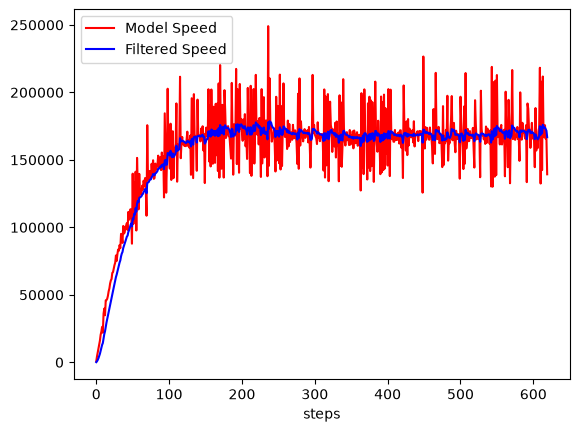

In [8]:
#
# filter_motor.py
#
import arslabrobotics as ar
import numpy as np

data = np.loadtxt("motor_data.txt")
(rows, _) = data.shape

alpha = 0.85
fltr = ar.identification.ARXModel([-alpha], [1 - alpha])
# y(k) + a0 * y(k-1) = b0 * u(k) 
# y(k) = alpha * y(k-1) + (1-alpha) * u(k)
# y(k) - alpha * y(k-1) = (1 - alpha) * u(k)

dp = ar.data.DataPlotter()
dp.set_x("steps")
dp.add_y("speed_m", "Model Speed")
dp.add_y("speed_f", "Filtered Speed")

data_file = open("motor_data_filtered.txt", "w")

t = 0
for i in range(rows):
    y_measure = data[i, 1]
    y_filtered = fltr.evaluate(y_measure)
    dp.append_x(t)
    dp.append_y("speed_m", y_measure)
    dp.append_y("speed_f", y_filtered)
    t += 1
    data_file.write(f"{data[i, 0]} {y_filtered}\n")

dp.plot()
data_file.close()
